# Synthetic Results Analysis

This notebook analyzes outputs produced by `scripts/run_synthetic_results.py`: multi-seed metrics, global curves, patient-specific surfaces, confidence intervals, and non-parametric statistical tests.

In [2]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src").exists():
    for parent in Path.cwd().parents:
        if (parent / "src").exists():
            PROJECT_ROOT = parent
            break
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.analysis.results_analysis import (
    available_metrics,
    export_analysis_tables,
    load_global_curves,
    load_patient_curves,
    load_patient_metadata,
    load_results_metrics,
    make_publication_table,
    metric_spec_available,
    non_oracle_methods,
    plot_global_curves,
    plot_method_metrics_ci_grid,
    plot_patient_surface_from_table,
    plot_patient_surface_gallery_from_table,
    print_statistical_tables,
    run_statistical_tests,
    save_figure,
    set_plot_theme,
    statistical_test_table,
    summarize_metric_ci,
)

set_plot_theme(style="whitegrid", context="notebook", font_scale=1.0)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 260)
pd.set_option("display.expand_frame_repr", False)
PROJECT_ROOT
# Force white background in rendered and saved figures.
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["savefig.facecolor"] = "white"
plt.rcParams["savefig.edgecolor"] = "white"


## Editable Configuration

Set `RESULTS_DIR` to the output directory generated by `run_synthetic_results.py`. Method names are normalized when curve tables are loaded, so names such as `Weighted_PMMR` become `Weighted PMMR`.

In [3]:
RESULTS_DIR = PROJECT_ROOT / "results" / "semisynthetic_article"

# Set to None to analyze all available seeds. The range below keeps seeds 1..10 inclusive.
SEEDS_TO_ANALYZE = list(range(1, 11))
SEED_LABEL = "all_seeds" if SEEDS_TO_ANALYZE is None else f"seeds_{min(SEEDS_TO_ANALYZE)}_{max(SEEDS_TO_ANALYZE)}"
ANALYSIS_DIR = RESULTS_DIR / "analysis" / SEED_LABEL
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

DEFAULT_SPLIT = "test"
ALPHA = 0.05
CONFIDENCE = 0.95

# Optional clipping for RMSE figure y-axes so extreme outliers (e.g., NMMR-U) do not hide other methods.
RMSE_YMAX_EXCLUDE_FAMILIES = ["NMMR-U", 'Weighted NMMR-U']
RMSE_YMAX_MARGIN_RATIO = 0.08

METHOD_ORDER = [
    "PMMR",
    "Weighted PMMR",
    "NMMR-U",
    "Weighted NMMR-U",
    "NMMR-V",
    "Weighted NMMR-V",
    "NMMR",
    "Weighted NMMR",
    "KPV",
    "Weighted KPV",
    "DFPV",
    "Weighted DFPV",
    "DR-KPV",
    "DR-PMMR conditional",
    "DR-PMMR marginal",
    "S-Learner",
    "Naive OOSR",
    "Oracle S-Learner",
    "Oracle Naive OOSR",
]

METHOD_LABELS = {
    "Weighted PMMR": "DA-PMMR",
    "Weighted NMMR-U": "DA-NMMR-U",
    "Weighted NMMR-V": "DA-NMMR-V",
    "NMMR": "NMMR",
    "Weighted NMMR": "DA-NMMR",
    "Weighted KPV": "DA-KPV",
    "Weighted DFPV": "DA-DFPV",
    "DR-PMMR conditional": "DR-PMMR cond.",
    "DR-PMMR marginal": "DR-PMMR marg.",
    "Naive OOSR": "W-S-Learner",
    "Oracle S-Learner": "Oracle",
    "Oracle Naive OOSR": "OOSR oracle",
    "ground_truth_oracle_conditioned": "Ground truth",
    "causal_marginal": "Causal marginal",
    "proxy_conditioned": "Proxy-conditioned",
    "structure_term": "Structure term",
    "ground_truth_causal": "Ground truth E[Y(a)|X]",
    "associational": "E[Y|X,A] reference",
    "oracle_conditioned": "Oracle-conditioned",
}

METHOD_COLORS = {
    "PMMR": "#1f77b4",
    "Weighted PMMR": "#17becf",
    "NMMR-U": "#ff7f0e",
    "Weighted NMMR-U": "#d62728",
    "NMMR-V": "#e377c2",
    "Weighted NMMR-V": "#9467bd",
    "NMMR": "#9edae5",
    "Weighted NMMR": "#8c564b",
    "KPV": "#2ca02c",
    "Weighted KPV": "#8c564b",
    "DFPV": "#bcbd22",
    "Weighted DFPV": "#8c9a2b",
    "DR-KPV": "#7f7f7f",
    "DR-PMMR conditional": "#aec7e8",
    "DR-PMMR marginal": "#ffbb78",
    "S-Learner": "#7f7f7f",
    "Naive OOSR": "#8c564b",
    "Oracle S-Learner": "#5254a3",
    "Oracle Naive OOSR": "#8ca252",
}

METHOD_LINESTYLES = {
    "PMMR": "-",
    "Weighted PMMR": "--",
    "NMMR-U": "-",
    "Weighted NMMR-U": "--",
    "NMMR-V": "-",
    "Weighted NMMR-V": "--",
    "NMMR": "-.",
    "Weighted NMMR": ":",
    "KPV": "-",
    "Weighted KPV": ":",
    "DFPV": "-.",
    "Weighted DFPV": "--",
    "DR-KPV": "--",
    "DR-PMMR conditional": "-.",
    "DR-PMMR marginal": ":",
    "S-Learner": "-",
    "Naive OOSR": "--",
    "Oracle S-Learner": "-.",
    "Oracle Naive OOSR": ":",
}

METRICS_TO_PLOT = [
    "val_regret",
    "factual_mean_rmse",
    "global_rmse",
    "local_rmse",
    "mean_curve_rmse",
    "mean_curve_argmax_abs_error",
    "regret_causal_marginal",
    "policy_mse_causal_marginal",
    "policy_value_causal_marginal",
]

METRIC_LABELS = {
    "val_regret": "Validation regret",
    "factual_mean_rmse": "Factual RMSE",
    "global_rmse": "Counterfactual RMSE",
    "local_rmse": "Local RMSE",
    "mean_curve_rmse": "Mean curve RMSE",
    "mean_curve_argmax_abs_error": "Argmax absolute error",
    "regret_causal_marginal": "Policy regret",
    "policy_mse_causal_marginal": "Policy MSE",
    "policy_value_causal_marginal": "Policy value",
}

METRIC_DIRECTIONS = {
    "policy_value_causal_marginal": True,
    "policy_value_oracle": True,
    "policy_value_structural": True,
}

NON_SHOWN_MODELS = ['NMMR', 'Weighted NMMR', 'Oracle S-Learner', 'Oracle Naive OOSR']

RESULTS_DIR, ANALYSIS_DIR

(WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/semisynthetic_article'),
 WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/semisynthetic_article/analysis/seeds_1_10'))

## Load Result Tables

The optional `SEEDS_TO_ANALYZE` selector is applied immediately after loading. All summaries, plots, and statistical tests below use only this subset.


In [4]:
metrics_df = load_results_metrics(RESULTS_DIR)
if SEEDS_TO_ANALYZE is not None:
    seed_set = {int(seed) for seed in SEEDS_TO_ANALYZE}
    metrics_df = metrics_df[metrics_df["seed"].astype("Int64").isin(seed_set)].copy()

global_curves_df = load_global_curves(RESULTS_DIR, seeds=SEEDS_TO_ANALYZE)
patient_curves_df = load_patient_curves(RESULTS_DIR, seeds=SEEDS_TO_ANALYZE)
patient_metadata_df = load_patient_metadata(RESULTS_DIR, seeds=SEEDS_TO_ANALYZE)

# Filtering models listed in NON_SHOWN_MODELS affects every downstream plot/table using these dataframes.
hidden_methods = {str(method) for method in NON_SHOWN_MODELS}
if hidden_methods:
    metrics_df = metrics_df[~metrics_df['method'].astype(str).isin(hidden_methods)].copy()
    global_curves_df = global_curves_df[~global_curves_df['method'].astype(str).isin(hidden_methods)].copy()
    patient_curves_df = patient_curves_df[~patient_curves_df['method'].astype(str).isin(hidden_methods)].copy()

selected_seeds = sorted(metrics_df["seed"].dropna().astype(int).unique().tolist())
print(f"selected seeds: {selected_seeds}")
print(f"analysis_dir: {ANALYSIS_DIR}")
print(f"metrics: {metrics_df.shape}")
print(f"global_curves: {global_curves_df.shape}")
print(f"patient_curves: {patient_curves_df.shape}")
print(f"patient_metadata: {patient_metadata_df.shape}")
display(metrics_df.head())
display(patient_curves_df[["raw_method", "method"]].drop_duplicates().sort_values("method"))


selected seeds: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
analysis_dir: C:\Users\Alex\CODE\optimal_treatment_proximal_inference\weighted_proximal_oosr\results\semisynthetic_article\analysis\seeds_1_10
metrics: (240, 45)
global_curves: (13260, 10)
patient_curves: (408000, 18)
patient_metadata: (500, 24)


,dataset,seed,split,model_key,method,run_dir,factual_mean_mae,factual_mean_rmse,global_rmse,kpv_lambda1,kpv_lambda2,local_rmse,mean_curve_argmax_abs_error,mean_curve_bias,mean_curve_direct_argmax_abs_error,mean_curve_direct_bias,mean_curve_direct_mae,mean_curve_direct_pred_argmax,mean_curve_direct_rmse,mean_curve_direct_true_argmax,mean_curve_mae,mean_curve_pred_argmax,mean_curve_rmse,mean_curve_true_argmax,observed_rmse,optimal_policy_value,optimal_policy_value_causal_marginal,optimal_policy_value_oracle,optimal_policy_value_structural,policy_mse,policy_mse_causal_marginal,policy_mse_oracle,policy_mse_structural,policy_value,policy_value_causal_marginal,policy_value_oracle,policy_value_structural,pseudo_outcome_iqr,pseudo_outcome_std,regret,regret_causal_marginal,regret_oracle,regret_structural,weight_ess_final,raw_method
0,semisynthetic_tcga,1,test,dfpv,DFPV,results/semisynthetic_article/runs_append/append_20260505_113554_110432/seed_0001,0.326476,0.485927,0.810108,NaN,NaN,0.197533,0.06,-0.276110,0.06,-0.280228,0.289056,0.48,0.421372,0.54,0.276110,0.48,0.352638,0.54,0.708905,0.107159,0.107159,0.248326,0.094711,0.051038,0.051038,0.102097,0.057582,-0.022141,-0.022141,0.001667,-0.023886,0.759005,1.248743,0.129299,0.129299,0.246659,0.118597,NaN,DFPV
1,semisynthetic_tcga,1,test,kpv,KPV,results/semisynthetic_article/runs_append/append_20260506_105532_806814/seed_0001,0.412431,0.599990,0.328296,0.01,0.3,0.180331,0.28,0.142393,0.28,0.143085,0.163797,0.82,0.228068,0.54,0.163553,0.82,0.227615,0.54,0.599134,0.107159,0.107159,0.248326,0.094711,0.087472,0.087472,0.141704,0.091754,-0.069241,-0.069241,-0.056439,-0.069460,0.007588,0.008600,0.176399,0.176399,0.304765,0.164171,NaN,KPV
2,semisynthetic_tcga,1,test,nmmr_u,NMMR-U,results/semisynthetic_article/runs_append/append_20260505_113554_110432/seed_0001,0.323548,0.463786,0.510681,NaN,NaN,0.230066,0.28,-0.052643,0.46,0.070335,0.190714,1.00,0.238119,0.54,0.175857,0.26,0.202717,0.54,0.344591,0.107159,0.107159,0.248326,0.094711,0.124672,0.124672,0.183447,0.131909,-0.177923,-0.177923,-0.156814,-0.179227,0.726458,0.808860,0.190054,0.190054,0.270093,0.182625,NaN,NMMR-U
3,semisynthetic_tcga,1,test,nmmr_v,NMMR-V,results/semisynthetic_article/runs_append/append_20260505_113554_110432/seed_0001,0.304459,0.447087,0.449899,NaN,NaN,0.175381,0.02,-0.027534,0.04,-0.052496,0.099133,0.50,0.110079,0.54,0.106582,0.52,0.121298,0.54,0.308143,0.107159,0.107159,0.248326,0.094711,0.107457,0.107457,0.167629,0.114794,-0.140212,-0.140212,-0.119762,-0.142005,0.569489,0.671714,0.247371,0.247371,0.368087,0.236715,NaN,NMMR-V
4,semisynthetic_tcga,1,test,naive_oosr,Naive OOSR,results/semisynthetic_article/runs_append/append_20260505_113554_110432/seed_0001,NaN,NaN,0.668947,NaN,NaN,0.281822,0.46,-0.065768,NaN,NaN,NaN,NaN,NaN,NaN,0.170967,1.00,0.198492,0.54,0.416008,0.107159,0.107159,0.248326,0.094711,0.120871,0.120871,0.179512,0.128939,-0.171955,-0.171955,-0.151155,-0.173998,NaN,NaN,0.279114,0.279114,0.399481,0.268709,1603.576937,Naive OOSR


,raw_method,method
153,DFPV,DFPV
280704,KPV,KPV
51,NMMR_U,NMMR-U
102,NMMR_V,NMMR-V
510,Naive_OOSR,Naive OOSR
0,PMMR,PMMR
459,S_Learner,S-Learner
357,Weighted_DFPV,Weighted DFPV
280755,Weighted_KPV,Weighted KPV
255,Weighted_NMMR_U,Weighted NMMR-U


In [5]:
available_test_metrics = available_metrics(metrics_df, split=DEFAULT_SPLIT)
metrics_to_use = [
    metric for metric in METRICS_TO_PLOT
    if metric_spec_available(metrics_df, metric, split=DEFAULT_SPLIT)
]
# Methods with both standard and DA (weighted) variants in METHOD_ORDER.
PROXIMAL_DA_BASE_METHODS = [
    method for method in METHOD_ORDER
    if not str(method).startswith("Weighted ") and f"Weighted {method}" in set(METHOD_ORDER)
]
DA_PATTERN_MAP = {"standard": None, "DA": "//..."}
# Explicit non-proximal pairing also rendered as standard/DA in the metric grid.
METHOD_FAMILY_MODE_OVERRIDES = {
    "S-Learner": ("S-Learner", "standard"),
    "Naive OOSR": ("Naive OOSR", "standard"),
    "DA-S-Learner": ("S-Learner", "DA"),
}
def ordered_existing_methods(available_methods):
    available = [str(method) for method in available_methods if pd.notna(method)]
    ordered = [method for method in METHOD_ORDER if method in set(available)]
    ordered += sorted(method for method in available if method not in set(ordered))
    return ordered
def _split_family_mode(method_name: str) -> tuple[str, str]:
    method_name = str(method_name)
    if method_name in METHOD_FAMILY_MODE_OVERRIDES:
        family, mode = METHOD_FAMILY_MODE_OVERRIDES[method_name]
        return str(family), str(mode)
    if method_name.startswith("Weighted "):
        base = method_name[len("Weighted "):]
        if base in PROXIMAL_DA_BASE_METHODS:
            return base, "DA"
    return method_name, "standard"
def _ordered_families_from_methods(observed_families):
    observed = {str(family) for family in observed_families}
    ordered = []
    for method in METHOD_ORDER:
        family, _ = _split_family_mode(str(method))
        if family in observed and family not in ordered:
            ordered.append(family)
    ordered.extend(sorted(family for family in observed if family not in set(ordered)))
    return ordered
def _family_color_map(families):
    out = {}
    for family in families:
        if family in METHOD_COLORS:
            out[family] = METHOD_COLORS[family]
        elif f"Weighted {family}" in METHOD_COLORS:
            out[family] = METHOD_COLORS[f"Weighted {family}"]
        else:
            out[family] = "tab:blue"
    return out
def _build_metric_plot_df(metrics_df, summary_df, metrics):
    rows = []
    source_map = (
        summary_df.loc[summary_df["metric"].isin(metrics), ["metric", "source_split", "source_metric"]]
        .drop_duplicates()
    )
    for _, source_row in source_map.iterrows():
        metric = str(source_row["metric"])
        split_name = str(source_row["source_split"])
        source_metric = str(source_row["source_metric"])
        if source_metric not in metrics_df.columns:
            continue
        frame = metrics_df.copy()
        if "split" in frame.columns:
            frame = frame[frame["split"].astype(str) == split_name]
        if frame.empty:
            continue
        tmp = frame[["method", source_metric]].copy()
        tmp["value"] = pd.to_numeric(tmp[source_metric], errors="coerce")
        tmp = tmp[tmp["value"].notna()].copy()
        if tmp.empty:
            continue
        tmp["metric"] = metric
        rows.append(tmp[["method", "metric", "value"]])
    if not rows:
        return pd.DataFrame(columns=["method", "metric", "value", "family", "mode"])
    plot_df = pd.concat(rows, ignore_index=True)
    family_mode = plot_df["method"].astype(str).map(_split_family_mode)
    plot_df["family"] = [family for family, _ in family_mode]
    plot_df["mode"] = [mode for _, mode in family_mode]
    return plot_df

def _rmse_axis_upper_limit(metric_name: str, metric_df: pd.DataFrame):
    metric_name = str(metric_name).lower()
    if "rmse" not in metric_name:
        return None
    values = metric_df.copy()
    if "family" in values.columns:
        values = values[~values["family"].astype(str).isin(set(RMSE_YMAX_EXCLUDE_FAMILIES))]
    series = pd.to_numeric(values.get("value"), errors="coerce")
    series = series[series.notna()]
    if series.empty:
        series = pd.to_numeric(metric_df.get("value"), errors="coerce")
        series = series[series.notna()]
    if series.empty:
        return None
    ymax = float(series.max())
    if ymax <= 0:
        return None
    return ymax * (1.0 + float(RMSE_YMAX_MARGIN_RATIO))
def plot_method_metrics_ci_grid_da_grouped(
    metrics_df,
    summary_df,
    metrics,
    *,
    metric_labels=None,
    ncols=3,
    figsize_per_panel=(5.4, 4.2),
    pattern_map=None,
    confidence=0.95,
    n_boot=2000,
    bootstrap_seed=13,
    title="Method metrics with bootstrap confidence intervals",
):
    import math
    import numpy as np
    import seaborn as sns
    import matplotlib.pyplot as plt
    from matplotlib.patches import Patch
    pattern_map = pattern_map or DA_PATTERN_MAP
    plot_df = _build_metric_plot_df(metrics_df, summary_df, metrics)
    if plot_df.empty:
        raise ValueError("No metric rows available to draw the metric grid.")
    available_metrics_set = set(plot_df["metric"].astype(str))
    metrics = [metric for metric in metrics if metric in available_metrics_set]
    if not metrics:
        raise ValueError("None of the requested metrics are present in the plot table.")
    nrows = int(math.ceil(len(metrics) / ncols))
    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(figsize_per_panel[0] * ncols, figsize_per_panel[1] * nrows),
        squeeze=False,
    )
    confidence_pct = int(round(float(confidence) * 100))
    mode_order = ["standard", "DA"]
    mode_label_map = {"standard": "Standard", "DA": "Decision-Aware"}
    for ax, metric in zip(axes.ravel(), metrics):
        metric_df = plot_df[plot_df["metric"].astype(str) == str(metric)].copy()
        if metric_df.empty:
            ax.axis("off")
            continue
        family_order = _ordered_families_from_methods(metric_df["family"].dropna().unique())
        color_map = _family_color_map(family_order)
        sns.barplot(
            data=metric_df,
            x="family",
            y="value",
            hue="mode",
            order=family_order,
            hue_order=mode_order,
            estimator=np.mean,
            errorbar=("ci", confidence_pct),
            n_boot=int(n_boot),
            seed=int(bootstrap_seed),
            dodge=True,
            edgecolor="black",
            linewidth=0.8,
            alpha=0.9,
            ax=ax,
        )
        tick_positions = np.asarray(ax.get_xticks(), dtype=float)
        present_modes = [mode for mode in mode_order if mode in set(metric_df["mode"].astype(str))]
        one_mode_only = len(present_modes) == 1
        single_mode = present_modes[0] if one_mode_only else None
        for patch in ax.patches:
            center_x = patch.get_x() + patch.get_width() / 2.0
            family_idx = int(np.argmin(np.abs(tick_positions - center_x)))
            family = family_order[family_idx]
            if one_mode_only:
                mode = single_mode
            else:
                mode = "standard" if center_x <= tick_positions[family_idx] else "DA"
            patch.set_facecolor(color_map[family])
            hatch = pattern_map.get(mode)
            if hatch:
                patch.set_hatch(hatch)
        tick_labels = [METHOD_LABELS.get(family, family) for family in family_order]
        ax.set_xticks(tick_positions)
        ax.set_xticklabels(tick_labels, rotation=30, ha="right")
        rmse_ymax = _rmse_axis_upper_limit(metric, metric_df)
        if rmse_ymax is not None:
            ax.set_ylim(top=rmse_ymax)
        metric_label = metric_labels.get(metric, metric.replace("_", " ")) if metric_labels else metric.replace("_", " ")
        ax.set_title(metric_label)
        ax.set_ylabel(metric_label)
        ax.set_xlabel("")
        ax.grid(axis="y", alpha=0.25)
        legend = ax.get_legend()
        if legend is not None:
            legend.remove()
    for ax in axes.ravel()[len(metrics):]:
        ax.axis("off")
    common_handles = [
        Patch(facecolor="lightgray", edgecolor="black", hatch=pattern_map.get(mode) or "", label=mode_label_map[mode])
        for mode in mode_order
        if mode in set(plot_df["mode"].astype(str))
    ]
    if common_handles:
        fig.legend(
            handles=common_handles,
            loc="upper center",
            bbox_to_anchor=(0.5, 1.01),
            ncol=max(1, len(common_handles)),
            frameon=False,
            title=None,
        )
    fig.suptitle(title, y=1.045)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    return fig

def plot_method_metrics_boxplot_grid_da_grouped(
    metrics_df,
    summary_df,
    metrics,
    *,
    metric_labels=None,
    ncols=3,
    figsize_per_panel=(5.4, 4.2),
    pattern_map=None,
    title="Method metric distributions (boxplot)",
):
    import math
    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib.patches import Patch
    pattern_map = pattern_map or DA_PATTERN_MAP
    plot_df = _build_metric_plot_df(metrics_df, summary_df, metrics)
    if plot_df.empty:
        raise ValueError("No metric rows available to draw the metric distribution grid.")
    available_metrics_set = set(plot_df["metric"].astype(str))
    metrics = [metric for metric in metrics if metric in available_metrics_set]
    if not metrics:
        raise ValueError("None of the requested metrics are present in the plot table.")
    nrows = int(math.ceil(len(metrics) / ncols))
    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(figsize_per_panel[0] * ncols, figsize_per_panel[1] * nrows),
        squeeze=False,
    )
    mode_order = ["standard", "DA"]
    mode_label_map = {"standard": "standard", "DA": "DA"}
    for ax, metric in zip(axes.ravel(), metrics):
        metric_df = plot_df[plot_df["metric"].astype(str) == str(metric)].copy()
        if metric_df.empty:
            ax.axis("off")
            continue
        family_order = _ordered_families_from_methods(metric_df["family"].dropna().unique())
        color_map = _family_color_map(family_order)
        present_modes = [mode for mode in mode_order if mode in set(metric_df["mode"].astype(str))]
        mode_cycle = present_modes or ["standard"]
        n_modes = len(mode_cycle)
        base_width = 0.34 if n_modes > 1 else 0.50
        for family_idx, family in enumerate(family_order):
            for mode_idx, mode in enumerate(mode_cycle):
                values = pd.to_numeric(
                    metric_df[(metric_df["family"].astype(str) == family) & (metric_df["mode"].astype(str) == mode)]["value"],
                    errors="coerce",
                ).dropna()
                if values.empty:
                    continue
                if n_modes == 1:
                    xpos = float(family_idx)
                else:
                    offset = (-0.5 + mode_idx) * base_width
                    xpos = float(family_idx) + offset
                artists = ax.boxplot(
                    [values.to_numpy(dtype=float)],
                    positions=[xpos],
                    widths=base_width * 0.92,
                    patch_artist=True,
                    showfliers=False,
                    manage_ticks=False,
                    boxprops={"linewidth": 0.9, "edgecolor": "black"},
                    medianprops={"linewidth": 1.1, "color": "black"},
                    whiskerprops={"linewidth": 0.9, "color": "black"},
                    capprops={"linewidth": 0.9, "color": "black"},
                )
                box = artists["boxes"][0]
                box.set_facecolor(color_map[family])
                hatch = pattern_map.get(mode)
                if hatch:
                    box.set_hatch(hatch)
        tick_positions = np.arange(len(family_order), dtype=float)
        tick_labels = [METHOD_LABELS.get(family, family) for family in family_order]
        ax.set_xticks(tick_positions)
        ax.set_xticklabels(tick_labels, rotation=30, ha="right")
        rmse_ymax = _rmse_axis_upper_limit(metric, metric_df)
        if rmse_ymax is not None:
            ax.set_ylim(bottom=0.0, top=rmse_ymax)
        metric_label = metric_labels.get(metric, metric.replace("_", " ")) if metric_labels else metric.replace("_", " ")
        ax.set_title(metric_label)
        ax.set_ylabel(metric_label)
        ax.set_xlabel("")
        ax.grid(axis="y", alpha=0.25)
    for ax in axes.ravel()[len(metrics):]:
        ax.axis("off")
    common_handles = [
        Patch(facecolor="lightgray", edgecolor="black", hatch=pattern_map.get(mode) or "", label=mode_label_map[mode])
        for mode in mode_order
        if mode in set(plot_df["mode"].astype(str))
    ]
    if common_handles:
        fig.legend(
            handles=common_handles,
            loc="upper center",
            bbox_to_anchor=(0.5, 1.01),
            ncol=max(1, len(common_handles)),
            frameon=False,
            title=None,
        )
    fig.suptitle(title, y=1.045)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    return fig
print("Available test metrics:")
print(available_test_metrics)
print("Selected metric specifications:")
print(metrics_to_use)
print("Proximal DA families:")
print(PROXIMAL_DA_BASE_METHODS)



Available test metrics:
['factual_mean_mae', 'factual_mean_rmse', 'global_rmse', 'kpv_lambda1', 'kpv_lambda2', 'local_rmse', 'mean_curve_argmax_abs_error', 'mean_curve_bias', 'mean_curve_direct_argmax_abs_error', 'mean_curve_direct_bias', 'mean_curve_direct_mae', 'mean_curve_direct_pred_argmax', 'mean_curve_direct_rmse', 'mean_curve_direct_true_argmax', 'mean_curve_mae', 'mean_curve_pred_argmax', 'mean_curve_rmse', 'mean_curve_true_argmax', 'observed_rmse', 'optimal_policy_value', 'optimal_policy_value_causal_marginal', 'optimal_policy_value_oracle', 'optimal_policy_value_structural', 'policy_mse', 'policy_mse_causal_marginal', 'policy_mse_oracle', 'policy_mse_structural', 'policy_value', 'policy_value_causal_marginal', 'policy_value_oracle', 'policy_value_structural', 'pseudo_outcome_iqr', 'pseudo_outcome_std', 'regret', 'regret_causal_marginal', 'regret_oracle', 'regret_structural', 'weight_ess_final']
Selected metric specifications:
['val_regret', 'factual_mean_rmse', 'global_rmse',

## Metric Tables With Confidence Intervals

In [6]:
summary_df = summarize_metric_ci(
    metrics_df,
    metrics_to_use,
    split=DEFAULT_SPLIT,
    confidence=CONFIDENCE,
)
publication_table = make_publication_table(summary_df, metrics=metrics_to_use)

written = export_analysis_tables(
    ANALYSIS_DIR,
    metric_summary=summary_df,
    publication_table=publication_table,
)
print(written)
display(summary_df.head(20))
display(publication_table)

{'metric_summary_ci': WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/semisynthetic_article/analysis/seeds_1_10/metric_summary_ci.csv'), 'publication_metric_table': WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/semisynthetic_article/analysis/seeds_1_10/publication_metric_table.csv')}


,dataset,model_key,method,metric,source_split,source_metric,n,mean,std,sem,ci_low,ci_high,ci_half_width
0,semisynthetic_tcga,dfpv,DFPV,val_regret,validation,regret,10,0.160704,0.054303,0.017172,0.121858,0.199551,0.038846
1,semisynthetic_tcga,kpv,KPV,val_regret,validation,regret,10,0.157277,0.026470,0.008371,0.138341,0.176212,0.018936
2,semisynthetic_tcga,naive_oosr,Naive OOSR,val_regret,validation,regret,10,0.240445,0.039733,0.012565,0.212022,0.268869,0.028423
3,semisynthetic_tcga,nmmr_u,NMMR-U,val_regret,validation,regret,10,0.290842,0.096616,0.030553,0.221727,0.359957,0.069115
4,semisynthetic_tcga,nmmr_v,NMMR-V,val_regret,validation,regret,10,0.229409,0.037871,0.011976,0.202318,0.256500,0.027091
5,semisynthetic_tcga,pmmr,PMMR,val_regret,validation,regret,10,0.127982,0.033652,0.010642,0.103909,0.152054,0.024073
6,semisynthetic_tcga,s_learner,S-Learner,val_regret,validation,regret,10,0.268649,0.018578,0.005875,0.255359,0.281938,0.013290
7,semisynthetic_tcga,weighted_dfpv,Weighted DFPV,val_regret,validation,regret,10,0.115071,0.036593,0.011572,0.088894,0.141248,0.026177
8,semisynthetic_tcga,weighted_kpv,Weighted KPV,val_regret,validation,regret,10,0.126146,0.009434,0.002983,0.119398,0.132895,0.006749
9,semisynthetic_tcga,weighted_nmmr_u,Weighted NMMR-U,val_regret,validation,regret,10,0.183789,0.064245,0.020316,0.137830,0.229747,0.045958


metric,val_regret,factual_mean_rmse,global_rmse,local_rmse,mean_curve_rmse,mean_curve_argmax_abs_error,regret_causal_marginal,policy_mse_causal_marginal,policy_value_causal_marginal
method,,,,,,,,,
DFPV,"0.161 [0.122, 0.200]","0.475 [0.458, 0.492]","0.592 [0.499, 0.684]","0.203 [0.190, 0.215]","0.194 [0.131, 0.258]","0.032 [0.015, 0.049]","0.160 [0.122, 0.197]","0.066 [0.049, 0.084]","-0.055 [-0.094, -0.015]"
KPV,"0.157 [0.138, 0.176]","0.609 [0.593, 0.626]","0.326 [0.321, 0.331]","0.184 [0.179, 0.189]","0.231 [0.225, 0.238]","0.300 [0.283, 0.317]","0.155 [0.136, 0.175]","0.076 [0.065, 0.086]","-0.050 [-0.071, -0.029]"
NMMR-U,"0.291 [0.222, 0.360]","220.884 [-210.108, 651.875]","325.323 [-319.077, 969.722]","229.506 [-224.182, 683.194]","295.644 [-295.156, 886.444]","0.436 [0.369, 0.503]","0.287 [0.223, 0.351]","0.195 [0.150, 0.240]","-0.325 [-0.422, -0.229]"
NMMR-V,"0.229 [0.202, 0.256]","0.459 [0.449, 0.470]","0.491 [0.465, 0.516]","0.194 [0.184, 0.205]","0.132 [0.117, 0.147]","0.056 [0.027, 0.085]","0.227 [0.203, 0.251]","0.099 [0.087, 0.111]","-0.122 [-0.148, -0.097]"
Naive OOSR,"0.240 [0.212, 0.269]",NaN,"0.681 [0.636, 0.726]","0.278 [0.261, 0.295]","0.176 [0.155, 0.197]","0.236 [0.092, 0.380]","0.234 [0.203, 0.264]","0.100 [0.087, 0.114]","-0.129 [-0.160, -0.098]"
PMMR,"0.128 [0.104, 0.152]","0.509 [0.498, 0.520]","0.374 [0.349, 0.399]","0.172 [0.160, 0.184]","0.110 [0.087, 0.133]","0.062 [0.045, 0.079]","0.127 [0.105, 0.148]","0.051 [0.041, 0.061]","-0.022 [-0.044, 0.001]"
S-Learner,"0.269 [0.255, 0.282]","0.417 [0.406, 0.429]","0.650 [0.616, 0.685]","0.273 [0.261, 0.285]","0.202 [0.180, 0.225]","0.476 [0.470, 0.482]","0.261 [0.246, 0.275]","0.112 [0.106, 0.119]","-0.156 [-0.171, -0.141]"
Weighted DFPV,"0.115 [0.089, 0.141]","0.539 [0.510, 0.569]","0.609 [0.528, 0.690]","0.257 [0.221, 0.294]","0.296 [0.246, 0.347]","0.086 [0.041, 0.131]","0.111 [0.087, 0.134]","0.048 [0.037, 0.058]","-0.006 [-0.029, 0.018]"
Weighted KPV,"0.126 [0.119, 0.133]","0.610 [0.593, 0.626]","0.324 [0.319, 0.329]","0.187 [0.181, 0.192]","0.229 [0.223, 0.236]","0.416 [0.385, 0.447]","0.125 [0.115, 0.134]","0.089 [0.082, 0.095]","-0.082 [-0.095, -0.069]"


## Metric Figures With Confidence Intervals

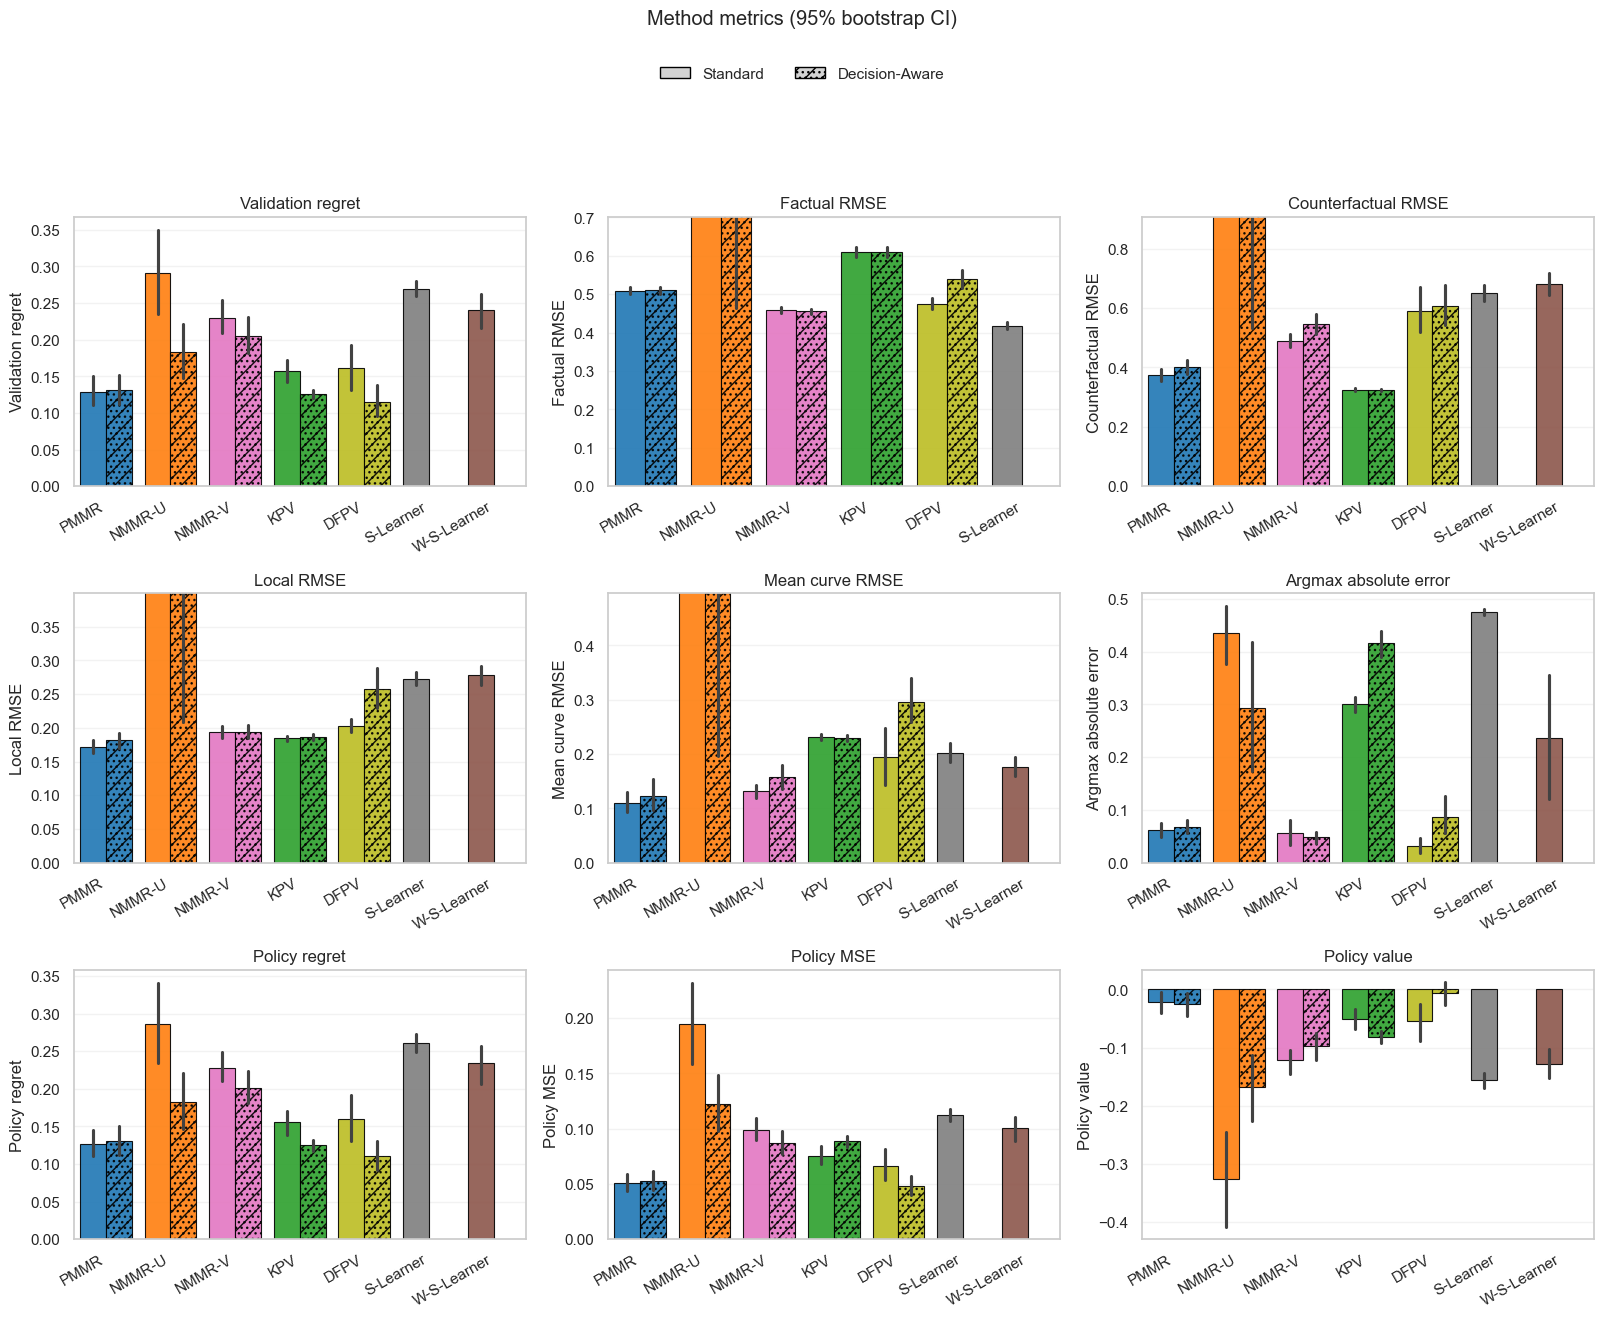

In [7]:
fig = plot_method_metrics_ci_grid_da_grouped(
    metrics_df,
    summary_df,
    metrics_to_use,
    metric_labels=METRIC_LABELS,
    ncols=3,
    pattern_map=DA_PATTERN_MAP,
    confidence=CONFIDENCE,
    n_boot=3000,
    bootstrap_seed=13,
    title=f"Method metrics ({int(CONFIDENCE * 100)}% bootstrap CI)",
)
save_figure(fig, ANALYSIS_DIR / "method_metrics_ci.png")
save_figure(fig, ANALYSIS_DIR / "method_metrics_ci.pdf")
plt.show()



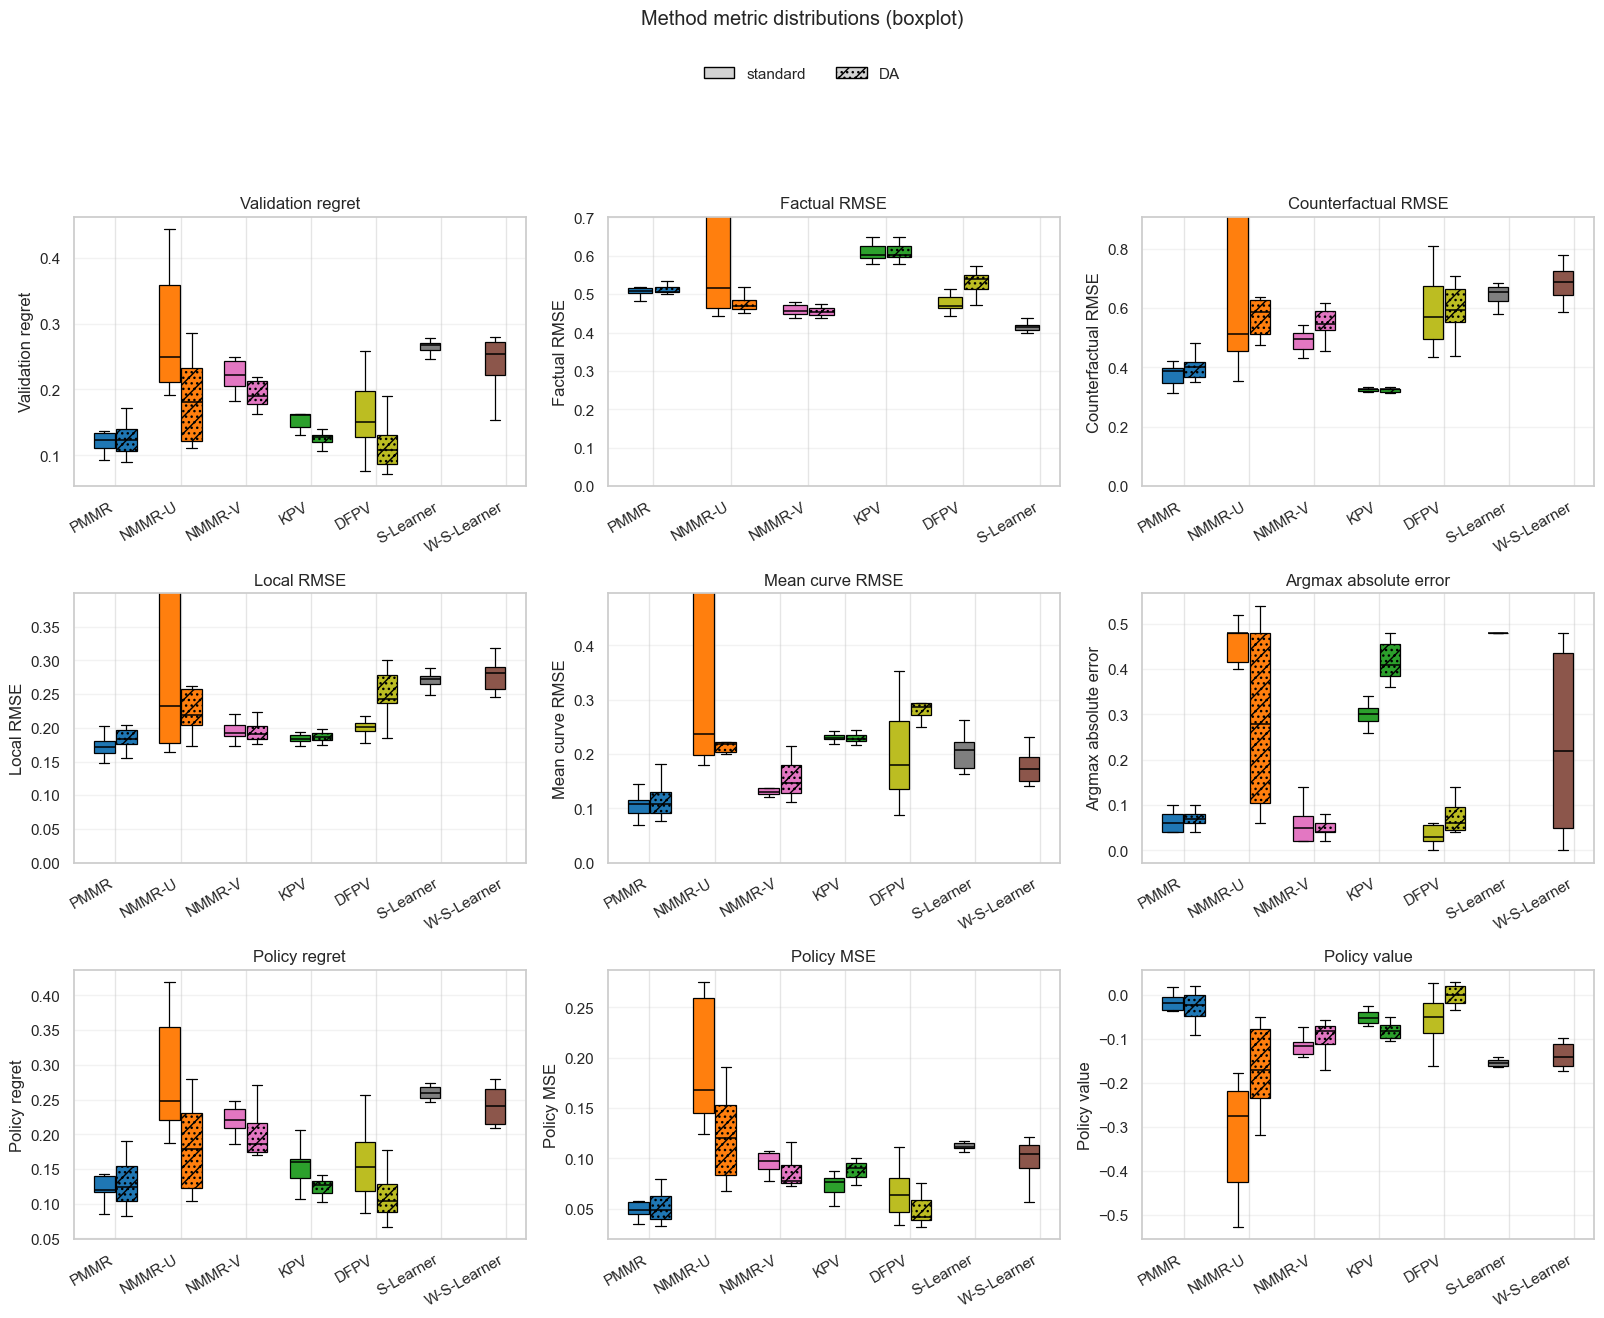

In [8]:
fig = plot_method_metrics_boxplot_grid_da_grouped(
    metrics_df,
    summary_df,
    metrics_to_use,
    metric_labels=METRIC_LABELS,
    ncols=3,
    pattern_map=DA_PATTERN_MAP,
    title="Method metric distributions (boxplot)",
)
save_figure(fig, ANALYSIS_DIR / "method_metrics_boxplot.png")
save_figure(fig, ANALYSIS_DIR / "method_metrics_boxplot.pdf")
plt.show()



C:\Users\Alex\AppData\Local\Temp\ipykernel_27664\2156293916.py:267: UserWarning: The figure layout has changed to tight
  fig.tight_layout(rect=(0, 0, 1, 0.94))


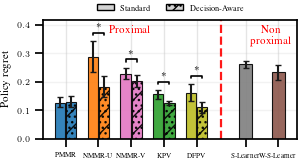

In [9]:
# Single-metric bar plot playground (editable)
import numpy as np
from matplotlib.patches import Patch
from src.analysis.stats import wilcoxon_paired_by_label
NON_PROXIMAL_FAMILIES_BAR = {"S-Learner", "Naive OOSR", "Oracle S-Learner", "Oracle Naive OOSR"}
SINGLE_METRIC_BAR = "regret_causal_marginal"   # e.g. "regret_causal_marginal", "factual_mean_rmse"
SINGLE_BAR_FIGSIZE = (6, 3.5)
SINGLE_BAR_FONT_SIZE = 11
SINGLE_BAR_N_BOOT = 3000
SINGLE_BAR_LEGEND_LOC = "upper center"
SINGLE_BAR_LEGEND_BBOX = (0.5, 1.20)
SINGLE_BAR_SAVE_STEM = f"single_metric_bar_{SINGLE_METRIC_BAR}"
# Extra horizontal space between proximal and non-proximal families.
BAR_GROUP_EXTRA_GAP = 0.5
BAR_SEPARATOR_COLOR = "red"
# Significance controls.
SINGLE_BAR_SIG_ENABLE = True
SINGLE_BAR_SIG_P = 0.05
SINGLE_BAR_SIG_USE_HOLM = True

plot_df_single = _build_metric_plot_df(metrics_df, summary_df, [SINGLE_METRIC_BAR])
metric_df = plot_df_single[plot_df_single["metric"].astype(str) == str(SINGLE_METRIC_BAR)].copy()
if metric_df.empty:
    raise ValueError(f"No data found for metric {SINGLE_METRIC_BAR!r}.")
family_order = _ordered_families_from_methods(metric_df["family"].dropna().unique())
proximal_families = [f for f in family_order if str(f) not in NON_PROXIMAL_FAMILIES_BAR]
non_proximal_families = [f for f in family_order if str(f) in NON_PROXIMAL_FAMILIES_BAR]
family_order = proximal_families + non_proximal_families
color_map = _family_color_map(family_order)
mode_order = ["standard", "DA"]
mode_label_map = {"standard": "Standard", "DA": "Decision-Aware"}
# Manual bar layout so families with only one mode are centered.
family_centers = np.arange(len(family_order), dtype=float)
if proximal_families and non_proximal_families:
    split_idx = len(proximal_families)
    family_centers[split_idx:] += BAR_GROUP_EXTRA_GAP
bar_width = 0.34
SINGLE_BAR_SOLO_WIDTH_MULT = 1.22


plt.rcParams.update({
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.edgecolor": "black",
    "axes.titlecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "legend.labelcolor": "black",
})


# Bootstrap CI helper (percentile interval)
def _bootstrap_ci(values: np.ndarray, n_boot: int, seed: int = 13, alpha: float = 0.05):
    arr = np.asarray(values, dtype=float)
    if arr.size == 0:
        return np.nan, np.nan
    if arr.size == 1:
        return float(arr[0]), float(arr[0])
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, arr.size, size=(int(n_boot), arr.size))
    means = arr[idx].mean(axis=1)
    low = float(np.quantile(means, alpha / 2.0))
    high = float(np.quantile(means, 1.0 - alpha / 2.0))
    return low, high

# Build paired DA/standard arrays per family from original rows.
def _paired_family_values_for_metric(metric_name: str):
    source_rows = summary_df.loc[summary_df["metric"].astype(str) == str(metric_name), ["source_split", "source_metric"]].drop_duplicates()
    if source_rows.empty:
        return {}
    split_name = str(source_rows.iloc[0]["source_split"])
    source_metric = str(source_rows.iloc[0]["source_metric"])
    if source_metric not in metrics_df.columns:
        return {}

    frame = metrics_df.copy()
    if "split" in frame.columns:
        frame = frame[frame["split"].astype(str) == split_name]
    if frame.empty:
        return {}

    frame = frame[[col for col in ["method", "dataset", "seed", "split", source_metric] if col in frame.columns]].copy()
    frame["value"] = pd.to_numeric(frame[source_metric], errors="coerce")
    frame = frame[frame["value"].notna()].copy()
    if frame.empty:
        return {}

    family_mode = frame["method"].astype(str).map(_split_family_mode)
    frame["family"] = [family for family, _ in family_mode]
    frame["mode"] = [mode for _, mode in family_mode]

    paired = {}
    for family in sorted(frame["family"].astype(str).unique()):
        fam = frame[frame["family"].astype(str) == family].copy()
        std = fam[fam["mode"].astype(str) == "standard"].copy()
        da = fam[fam["mode"].astype(str) == "DA"].copy()
        if std.empty or da.empty:
            continue

        keys = [k for k in ["dataset", "seed", "split"] if (k in std.columns and k in da.columns)]
        if keys:
            merged = std[keys + ["value"]].rename(columns={"value": "standard"}).merge(
                da[keys + ["value"]].rename(columns={"value": "DA"}),
                on=keys,
                how="inner",
            )
            da_vals = pd.to_numeric(merged["DA"], errors="coerce").to_numpy(dtype=float)
            std_vals = pd.to_numeric(merged["standard"], errors="coerce").to_numpy(dtype=float)
        else:
            da_vals = pd.to_numeric(da["value"], errors="coerce").to_numpy(dtype=float)
            std_vals = pd.to_numeric(std["value"], errors="coerce").to_numpy(dtype=float)
            n = int(min(da_vals.size, std_vals.size))
            da_vals = da_vals[:n]
            std_vals = std_vals[:n]

        mask = np.isfinite(da_vals) & np.isfinite(std_vals)
        da_vals = da_vals[mask]
        std_vals = std_vals[mask]
        if da_vals.size > 0:
            paired[family] = (da_vals, std_vals)
    return paired

from tueplots import bundles
with plt.rc_context(bundles.icml2024(column='half')):
    fig, ax = plt.subplots()
    fig.patch.set_facecolor("white")
    ax.set_facecolor("white")
    all_upper = []
    family_mode_meta = {}
    for family_idx, family in enumerate(family_order):
        center = family_centers[family_idx]
        family_mask = metric_df["family"].astype(str) == str(family)
        modes_present_family = [m for m in mode_order if np.any(family_mask & (metric_df["mode"].astype(str) == m))]
        if not modes_present_family:
            continue
        if len(modes_present_family) == 1:
            pos_by_mode = {modes_present_family[0]: center}
        else:
            pos_by_mode = {
                modes_present_family[0]: center - bar_width / 2.0,
                modes_present_family[1]: center + bar_width / 2.0,
            }
        family_mode_meta[str(family)] = {}
        for mode in modes_present_family:
            vals = pd.to_numeric(
                metric_df[family_mask & (metric_df["mode"].astype(str) == mode)]["value"],
                errors="coerce",
            ).dropna().to_numpy(dtype=float)
            if vals.size == 0:
                continue
            mean_val = float(np.mean(vals))
            ci_low, ci_high = _bootstrap_ci(vals, n_boot=SINGLE_BAR_N_BOOT, seed=13, alpha=1.0 - CONFIDENCE)
            yerr_low = max(0.0, mean_val - ci_low)
            yerr_high = max(0.0, ci_high - mean_val)
            bar = ax.bar(
                [pos_by_mode[mode]],
                [mean_val],
                width=(bar_width * SINGLE_BAR_SOLO_WIDTH_MULT) if len(modes_present_family) == 1 else (bar_width * 0.92),
                yerr=np.array([[yerr_low], [yerr_high]]),
                capsize=2,
                color=color_map[family],
                edgecolor="black",
                linewidth=0.8,
                alpha=0.9,
            )
            hatch = DA_PATTERN_MAP.get(mode)
            if hatch:
                bar[0].set_hatch(hatch)
            bar_top = mean_val + yerr_high
            all_upper.append(bar_top)
            family_mode_meta[str(family)][str(mode)] = {"x": float(pos_by_mode[mode]), "top": float(bar_top)}

    ax.set_xticks(family_centers)
    ax.set_xticklabels([METHOD_LABELS.get(family, family) for family in family_order], rotation=0
                       , fontsize=5.25
                       )
    # Slightly nudge non-proximal tick labels for readability.
    for tick_label in ax.get_xticklabels():
        text = str(tick_label.get_text()).strip()
        x, y = tick_label.get_position()
        if text == "S-Learner":
            tick_label.set_x(x - 0.08)
        elif text == "W-S-Learner":
            tick_label.set_x(x + 0.08)
    rmse_ymax = _rmse_axis_upper_limit(SINGLE_METRIC_BAR, metric_df)
    if rmse_ymax is not None:
        ax.set_ylim(top=rmse_ymax)
    elif all_upper:
        ax.set_ylim(top=max(all_upper) * 1.08)

    # Wilcoxon significance braces (DA vs standard) without changing bar style.
    if SINGLE_BAR_SIG_ENABLE:
        higher_is_better = bool(METRIC_DIRECTIONS.get(str(SINGLE_METRIC_BAR), False))
        alternative = "greater" if higher_is_better else "less"
        correction = "holm" if bool(SINGLE_BAR_SIG_USE_HOLM) else "uncorrected"
        paired_values = _paired_family_values_for_metric(SINGLE_METRIC_BAR)
        if paired_values:
            sig = wilcoxon_paired_by_label(
                paired_values,
                alpha=float(SINGLE_BAR_SIG_P),
                correction=correction,
                alternative=alternative,
            )
            y0, y1 = ax.get_ylim()
            y_span = max(1e-12, float(y1 - y0))
            brace_h = 0.02 * y_span
            brace_pad = 0.08 * y_span
            used_y = []
            for family in family_order:
                fam_key = str(family)
                result = sig.get(fam_key)
                if not result or not bool(result.get("rejected", False)):
                    continue
                mode_meta = family_mode_meta.get(fam_key, {})
                if "standard" not in mode_meta or "DA" not in mode_meta:
                    continue
                x_std = float(mode_meta["standard"]["x"])
                x_da = float(mode_meta["DA"]["x"])
                x_left, x_right = sorted([x_std, x_da])
                y_base = max(float(mode_meta["standard"]["top"]), float(mode_meta["DA"]["top"])) + brace_pad

                used_y.append(y_base)
                ax.plot([x_left, x_left, x_right, x_right], [y_base - brace_h, y_base, y_base, y_base - brace_h], color="black", linewidth=1.2)
                ax.text(0.5 * (x_left + x_right), y_base + 0.00005 * y_span, "*", ha="center", va="bottom"
                        # , fontsize=SINGLE_BAR_FONT_SIZE + 2
                        , color="black")
            if used_y:
                ax.set_ylim(top=max(ax.get_ylim()[1], max(used_y) + 0.12 * y_span))

    # Visual separator + labels.
    if proximal_families and non_proximal_families:
        split_idx = len(proximal_families)
        x_sep = 0.5 * (family_centers[split_idx - 1] + family_centers[split_idx])
        ax.axvline(x_sep, color=BAR_SEPARATOR_COLOR, linewidth=1.6, alpha=0.9, linestyle='--')
        y_top = ax.get_ylim()[1]
        y_text = y_top * 0.96
        ax.text(x_sep - 2.2, y_text, "Proximal", color=BAR_SEPARATOR_COLOR, ha="right", va="top"
                # , fontsize=max(8, SINGLE_BAR_FONT_SIZE - 1)
                )
        ax.text(x_sep + 1.5, y_text, "Non\nproximal", color=BAR_SEPARATOR_COLOR, ha="center", va="top",
                # fontsize=max(8, SINGLE_BAR_FONT_SIZE - 1)
                )
    ax.set_ylabel(METRIC_LABELS.get(SINGLE_METRIC_BAR, SINGLE_METRIC_BAR)
                  # , fontsize=SINGLE_BAR_FONT_SIZE
                  )
    ax.set_xlabel("")
    ax.tick_params(axis="y"
                   # , labelsize=SINGLE_BAR_FONT_SIZE
                   )
    ax.grid(axis="y", alpha=0.25)
    # Force axis/tick visibility in notebooks with custom themes.
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
    ax.tick_params(axis="both", which="both", colors="black", labelcolor="black", bottom=True, left=True, labelbottom=True, labelleft=True)
    ax.xaxis.label.set_color("black")
    ax.yaxis.label.set_color("black")
    legend_handles = [
        Patch(facecolor="lightgray", edgecolor="black", hatch=DA_PATTERN_MAP.get(mode) or "", label=mode_label_map[mode])
        for mode in mode_order if np.any(metric_df["mode"].astype(str) == mode)
    ]
    if legend_handles:
        ax.legend(handles=legend_handles, loc=SINGLE_BAR_LEGEND_LOC, bbox_to_anchor=SINGLE_BAR_LEGEND_BBOX, ncol=len(legend_handles), frameon=False, title=None
                  # , fontsize=SINGLE_BAR_FONT_SIZE
                  )
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    save_figure(fig, ANALYSIS_DIR / f"{SINGLE_BAR_SAVE_STEM}.png")
    save_figure(fig, ANALYSIS_DIR / f"{SINGLE_BAR_SAVE_STEM}.pdf")
    plt.show()




Summary for metric: global_rmse
family     mode   mean    std  n
  DFPV       DA 0.6086 0.1132 10
  DFPV standard 0.5918 0.1294 10
   KPV       DA 0.3243 0.0069 10
   KPV standard 0.3256 0.0068 10
NMMR-U       DA 1.0076 0.0121 10
NMMR-U standard 3.1688 6.0054 10
NMMR-V       DA 0.5470 0.0560 10
NMMR-V standard 0.4909 0.0358 10
  PMMR       DA 0.4005 0.0400 10
  PMMR standard 0.3744 0.0349 10


C:\Users\Alex\AppData\Local\Temp\ipykernel_27664\2993965623.py:296: UserWarning: The figure layout has changed to tight
  fig.tight_layout(rect=(0, 0, 1, 0.94))


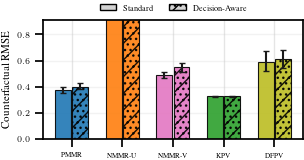

In [29]:
# Factual RMSE
import numpy as np
from matplotlib.patches import Patch
from src.analysis.stats import wilcoxon_paired_by_label
NON_PROXIMAL_FAMILIES_BAR = {"S-Learner", "Naive OOSR", "Oracle S-Learner", "Oracle Naive OOSR"}
SINGLE_METRIC_BAR = "global_rmse"   # e.g. "regret_causal_marginal", "factual_mean_rmse"
SINGLE_BAR_FIGSIZE = (6, 3.5)
SINGLE_BAR_FONT_SIZE = 11
SINGLE_BAR_N_BOOT = 3000
SINGLE_BAR_LEGEND_LOC = "upper center"
SINGLE_BAR_LEGEND_BBOX = (0.5, 1.20)
SINGLE_BAR_SAVE_STEM = f"single_metric_bar_{SINGLE_METRIC_BAR}"
# Extra horizontal space between proximal and non-proximal families.
BAR_GROUP_EXTRA_GAP = 0.5
BAR_SEPARATOR_COLOR = "red"
# Significance controls.
SINGLE_BAR_SIG_ENABLE = True
SINGLE_BAR_SIG_P = 0.05
SINGLE_BAR_SIG_USE_HOLM = True

#
RMSE_YMAX_EXCLUDE_FAMILIES = ["NMMR-U", 'Weighted NMMR-U']

plot_df_single = _build_metric_plot_df(metrics_df, summary_df, [SINGLE_METRIC_BAR])
metric_df = plot_df_single[plot_df_single["metric"].astype(str) == str(SINGLE_METRIC_BAR)].copy()

# Only for this plot: hide S-Learner
metric_df = metric_df[metric_df["family"].astype(str) != "S-Learner"].copy()
# Only for this plot: hide S-Learner
metric_df = metric_df[metric_df["family"].astype(str) != "Naive OOSR"].copy()

if metric_df.empty:
    raise ValueError(f"No data found for metric {SINGLE_METRIC_BAR!r}.")
family_order = _ordered_families_from_methods(metric_df["family"].dropna().unique())
proximal_families = [f for f in family_order if str(f) not in NON_PROXIMAL_FAMILIES_BAR]
non_proximal_families = [f for f in family_order if str(f) in NON_PROXIMAL_FAMILIES_BAR]
family_order = proximal_families + non_proximal_families
color_map = _family_color_map(family_order)
mode_order = ["standard", "DA"]
mode_label_map = {"standard": "Standard", "DA": "Decision-Aware"}
# Manual bar layout so families with only one mode are centered.
family_centers = np.arange(len(family_order), dtype=float)
if proximal_families and non_proximal_families:
    split_idx = len(proximal_families)
    family_centers[split_idx:] += BAR_GROUP_EXTRA_GAP
bar_width = 0.34
SINGLE_BAR_SOLO_WIDTH_MULT = 1.22


summary_table = (
    metric_df
    .groupby(["family", "mode"], as_index=False)["value"]
    .agg(mean="mean", std="std", n="count")
)

summary_table["mean"] = summary_table["mean"].round(4)
summary_table["std"] = summary_table["std"].round(4)

print(f"\nSummary for metric: {SINGLE_METRIC_BAR}")
print(summary_table.to_string(index=False))


plt.rcParams.update({
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.edgecolor": "black",
    "axes.titlecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "legend.labelcolor": "black",
})


# Bootstrap CI helper (percentile interval)
def _bootstrap_ci(values: np.ndarray, n_boot: int, seed: int = 13, alpha: float = 0.05):
    arr = np.asarray(values, dtype=float)
    if arr.size == 0:
        return np.nan, np.nan
    if arr.size == 1:
        return float(arr[0]), float(arr[0])
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, arr.size, size=(int(n_boot), arr.size))
    means = arr[idx].mean(axis=1)
    low = float(np.quantile(means, alpha / 2.0))
    high = float(np.quantile(means, 1.0 - alpha / 2.0))
    return low, high

# Build paired DA/standard arrays per family from original rows.
def _paired_family_values_for_metric(metric_name: str):
    source_rows = summary_df.loc[summary_df["metric"].astype(str) == str(metric_name), ["source_split", "source_metric"]].drop_duplicates()
    if source_rows.empty:
        return {}
    split_name = str(source_rows.iloc[0]["source_split"])
    source_metric = str(source_rows.iloc[0]["source_metric"])
    if source_metric not in metrics_df.columns:
        return {}

    frame = metrics_df.copy()
    if "split" in frame.columns:
        frame = frame[frame["split"].astype(str) == split_name]
    if frame.empty:
        return {}

    frame = frame[[col for col in ["method", "dataset", "seed", "split", source_metric] if col in frame.columns]].copy()
    frame["value"] = pd.to_numeric(frame[source_metric], errors="coerce")
    frame = frame[frame["value"].notna()].copy()
    if frame.empty:
        return {}

    family_mode = frame["method"].astype(str).map(_split_family_mode)
    frame["family"] = [family for family, _ in family_mode]
    frame["mode"] = [mode for _, mode in family_mode]

    paired = {}
    for family in sorted(frame["family"].astype(str).unique()):
        fam = frame[frame["family"].astype(str) == family].copy()
        std = fam[fam["mode"].astype(str) == "standard"].copy()
        da = fam[fam["mode"].astype(str) == "DA"].copy()
        if std.empty or da.empty:
            continue

        keys = [k for k in ["dataset", "seed", "split"] if (k in std.columns and k in da.columns)]
        if keys:
            merged = std[keys + ["value"]].rename(columns={"value": "standard"}).merge(
                da[keys + ["value"]].rename(columns={"value": "DA"}),
                on=keys,
                how="inner",
            )
            da_vals = pd.to_numeric(merged["DA"], errors="coerce").to_numpy(dtype=float)
            std_vals = pd.to_numeric(merged["standard"], errors="coerce").to_numpy(dtype=float)
        else:
            da_vals = pd.to_numeric(da["value"], errors="coerce").to_numpy(dtype=float)
            std_vals = pd.to_numeric(std["value"], errors="coerce").to_numpy(dtype=float)
            n = int(min(da_vals.size, std_vals.size))
            da_vals = da_vals[:n]
            std_vals = std_vals[:n]

        mask = np.isfinite(da_vals) & np.isfinite(std_vals)
        da_vals = da_vals[mask]
        std_vals = std_vals[mask]
        if da_vals.size > 0:
            paired[family] = (da_vals, std_vals)
    return paired

from tueplots import bundles
with plt.rc_context(bundles.icml2024(column='half')):
    fig, ax = plt.subplots()
    fig.patch.set_facecolor("white")
    ax.set_facecolor("white")
    all_upper = []
    family_mode_meta = {}
    for family_idx, family in enumerate(family_order):
        center = family_centers[family_idx]
        family_mask = metric_df["family"].astype(str) == str(family)
        modes_present_family = [m for m in mode_order if np.any(family_mask & (metric_df["mode"].astype(str) == m))]
        if not modes_present_family:
            continue
        if len(modes_present_family) == 1:
            pos_by_mode = {modes_present_family[0]: center}
        else:
            pos_by_mode = {
                modes_present_family[0]: center - bar_width / 2.0,
                modes_present_family[1]: center + bar_width / 2.0,
            }
        family_mode_meta[str(family)] = {}
        for mode in modes_present_family:
            vals = pd.to_numeric(
                metric_df[family_mask & (metric_df["mode"].astype(str) == mode)]["value"],
                errors="coerce",
            ).dropna().to_numpy(dtype=float)
            if vals.size == 0:
                continue
            mean_val = float(np.mean(vals))
            ci_low, ci_high = _bootstrap_ci(vals, n_boot=SINGLE_BAR_N_BOOT, seed=13, alpha=1.0 - CONFIDENCE)
            yerr_low = max(0.0, mean_val - ci_low)
            yerr_high = max(0.0, ci_high - mean_val)
            bar = ax.bar(
                [pos_by_mode[mode]],
                [mean_val],
                width=(bar_width * SINGLE_BAR_SOLO_WIDTH_MULT) if len(modes_present_family) == 1 else (bar_width * 0.92),
                yerr=np.array([[yerr_low], [yerr_high]]),
                capsize=2,
                color=color_map[family],
                edgecolor="black",
                linewidth=0.8,
                alpha=0.9,
            )
            hatch = DA_PATTERN_MAP.get(mode)
            if hatch:
                bar[0].set_hatch(hatch)
            bar_top = mean_val + yerr_high
            all_upper.append(bar_top)
            family_mode_meta[str(family)][str(mode)] = {"x": float(pos_by_mode[mode]), "top": float(bar_top)}

    ax.set_xticks(family_centers)
    ax.set_xticklabels([METHOD_LABELS.get(family, family) for family in family_order], rotation=0
                       , fontsize=5.25
                       )
    # Slightly nudge non-proximal tick labels for readability.
    for tick_label in ax.get_xticklabels():
        text = str(tick_label.get_text()).strip()
        x, y = tick_label.get_position()
        if text == "S-Learner":
            tick_label.set_x(x - 0.08)
        elif text == "W-S-Learner":
            tick_label.set_x(x + 0.08)
    rmse_ymax = _rmse_axis_upper_limit(SINGLE_METRIC_BAR, metric_df)
    if rmse_ymax is not None:
        ax.set_ylim(top=rmse_ymax)
    elif all_upper:
        ax.set_ylim(top=max(all_upper) * 1.08)

    # Wilcoxon significance braces (DA vs standard) without changing bar style.
    if SINGLE_BAR_SIG_ENABLE:
        higher_is_better = bool(METRIC_DIRECTIONS.get(str(SINGLE_METRIC_BAR), False))
        alternative = "greater" if higher_is_better else "less"
        correction = "holm" if bool(SINGLE_BAR_SIG_USE_HOLM) else "uncorrected"
        paired_values = _paired_family_values_for_metric(SINGLE_METRIC_BAR)
        if paired_values:
            sig = wilcoxon_paired_by_label(
                paired_values,
                alpha=float(SINGLE_BAR_SIG_P),
                correction=correction,
                alternative=alternative,
            )
            y0, y1 = ax.get_ylim()
            y_span = max(1e-12, float(y1 - y0))
            brace_h = 0.02 * y_span
            brace_pad = 0.08 * y_span
            used_y = []
            for family in family_order:
                fam_key = str(family)
                result = sig.get(fam_key)
                if not result or not bool(result.get("rejected", False)):
                    continue
                mode_meta = family_mode_meta.get(fam_key, {})
                if "standard" not in mode_meta or "DA" not in mode_meta:
                    continue
                x_std = float(mode_meta["standard"]["x"])
                x_da = float(mode_meta["DA"]["x"])
                x_left, x_right = sorted([x_std, x_da])
                y_base = max(float(mode_meta["standard"]["top"]), float(mode_meta["DA"]["top"])) + brace_pad

                used_y.append(y_base)
                #         # , fontsize=SINGLE_BAR_FONT_SIZE + 2
                #         , color="black")
            if used_y:
                ax.set_ylim(top=max(ax.get_ylim()[1], max(used_y) + 0.12 * y_span))

    # Visual separator + labels.
    if proximal_families and non_proximal_families:
        split_idx = len(proximal_families)
        x_sep = 0.5 * (family_centers[split_idx - 1] + family_centers[split_idx])
        #         # , fontsize=max(8, SINGLE_BAR_FONT_SIZE - 1)
        #         )
        #         # fontsize=max(8, SINGLE_BAR_FONT_SIZE - 1)
        #         )
    ax.set_ylabel(METRIC_LABELS.get(SINGLE_METRIC_BAR, SINGLE_METRIC_BAR)
                  # , fontsize=SINGLE_BAR_FONT_SIZE
                  )
    ax.set_xlabel("")
    ax.tick_params(axis="y"
                   # , labelsize=SINGLE_BAR_FONT_SIZE
                   )
    ax.grid(axis="y", alpha=0.25)
    # Force axis/tick visibility in notebooks with custom themes.
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
    ax.tick_params(axis="both", which="both", colors="black", labelcolor="black", bottom=True, left=True, labelbottom=True, labelleft=True)
    ax.xaxis.label.set_color("black")
    ax.yaxis.label.set_color("black")
    legend_handles = [
        Patch(facecolor="lightgray", edgecolor="black", hatch=DA_PATTERN_MAP.get(mode) or "", label=mode_label_map[mode])
        for mode in mode_order if np.any(metric_df["mode"].astype(str) == mode)
    ]
    if legend_handles:
        ax.legend(handles=legend_handles, loc=SINGLE_BAR_LEGEND_LOC, bbox_to_anchor=SINGLE_BAR_LEGEND_BBOX, ncol=len(legend_handles), frameon=False, title=None
                  # , fontsize=SINGLE_BAR_FONT_SIZE
                  )
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    save_figure(fig, ANALYSIS_DIR / f"{SINGLE_BAR_SAVE_STEM}.png")
    save_figure(fig, ANALYSIS_DIR / f"{SINGLE_BAR_SAVE_STEM}.pdf")
    plt.show()



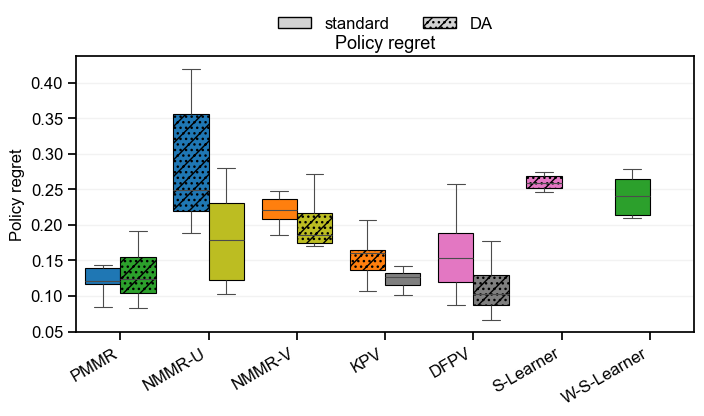

In [11]:
# Single-metric boxplot playground (editable)
import numpy as np
import seaborn as sns
from matplotlib.patches import Patch, PathPatch
SINGLE_METRIC_BOX = "regret_causal_marginal"   # e.g. "regret_causal_marginal", "factual_mean_rmse"
SINGLE_BOX_FIGSIZE = (7.2, 4.8)
SINGLE_BOX_FONT_SIZE = 12
SINGLE_BOX_SHOW_FLIERS = False
SINGLE_BOX_LEGEND_LOC = "upper center"
SINGLE_BOX_LEGEND_BBOX = (0.5, 1.20)
SINGLE_BOX_SAVE_STEM = f"single_metric_boxplot_{SINGLE_METRIC_BOX}"
plot_df_single = _build_metric_plot_df(metrics_df, summary_df, [SINGLE_METRIC_BOX])
metric_df = plot_df_single[plot_df_single["metric"].astype(str) == str(SINGLE_METRIC_BOX)].copy()
if metric_df.empty:
    raise ValueError(f"No data found for metric {SINGLE_METRIC_BOX!r}.")
family_order = _ordered_families_from_methods(metric_df["family"].dropna().unique())
color_map = _family_color_map(family_order)
mode_order = ["standard", "DA"]
present_modes = [mode for mode in mode_order if mode in set(metric_df["mode"].astype(str))]
mode_cycle = present_modes or ["standard"]
fig, ax = plt.subplots(figsize=SINGLE_BOX_FIGSIZE)
fig.patch.set_facecolor("white")
ax.set_facecolor("white")
sns.boxplot(
    data=metric_df,
    x="family",
    y="value",
    hue="mode",
    order=family_order,
    hue_order=mode_order,
    dodge=True,
    linewidth=0.8,
    showfliers=bool(SINGLE_BOX_SHOW_FLIERS),
    ax=ax,
)
expected_boxes = len(family_order) * len(mode_cycle)
box_patches = [patch for patch in ax.patches if isinstance(patch, PathPatch)]
if len(box_patches) >= expected_boxes:
    box_patches = box_patches[:expected_boxes]
for idx_patch, patch in enumerate(box_patches):
    family_idx = idx_patch // len(mode_cycle)
    if family_idx >= len(family_order):
        break
    mode = mode_cycle[idx_patch % len(mode_cycle)]
    family = family_order[family_idx]
    patch.set_facecolor(color_map[family])
    patch.set_edgecolor("black")
    hatch = DA_PATTERN_MAP.get(mode)
    if hatch:
        patch.set_hatch(hatch)
tick_positions = np.asarray(ax.get_xticks(), dtype=float)
ax.set_xticks(tick_positions)
ax.set_xticklabels([METHOD_LABELS.get(family, family) for family in family_order], rotation=30, ha="right", fontsize=SINGLE_BOX_FONT_SIZE)
rmse_ymax = _rmse_axis_upper_limit(SINGLE_METRIC_BOX, metric_df)
if rmse_ymax is not None:
    ax.set_ylim(bottom=0.0, top=rmse_ymax)
ax.set_title(METRIC_LABELS.get(SINGLE_METRIC_BOX, SINGLE_METRIC_BOX), fontsize=SINGLE_BOX_FONT_SIZE + 1)
ax.set_ylabel(METRIC_LABELS.get(SINGLE_METRIC_BOX, SINGLE_METRIC_BOX), fontsize=SINGLE_BOX_FONT_SIZE)
ax.set_xlabel("")
ax.tick_params(axis="y", labelsize=SINGLE_BOX_FONT_SIZE)
ax.grid(axis="y", alpha=0.25)
legend = ax.get_legend()
if legend is not None:
    legend.remove()

# Force axis/tick visibility in notebooks with custom themes.
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
ax.tick_params(axis="both", which="both", colors="black", labelcolor="black", bottom=True, left=True, labelbottom=True, labelleft=True)
ax.xaxis.label.set_color("black")
ax.yaxis.label.set_color("black")
ax.title.set_color("black")

legend_handles = [
    Patch(facecolor="lightgray", edgecolor="black", hatch=DA_PATTERN_MAP.get(mode) or "", label=mode)
    for mode in mode_order if mode in set(metric_df["mode"].astype(str))
]
if legend_handles:
    ax.legend(handles=legend_handles, loc=SINGLE_BOX_LEGEND_LOC, bbox_to_anchor=SINGLE_BOX_LEGEND_BBOX, ncol=len(legend_handles), frameon=False, title=None, fontsize=SINGLE_BOX_FONT_SIZE)
fig.tight_layout(rect=(0, 0, 1, 0.94))
save_figure(fig, ANALYSIS_DIR / f"{SINGLE_BOX_SAVE_STEM}.png")
save_figure(fig, ANALYSIS_DIR / f"{SINGLE_BOX_SAVE_STEM}.pdf")
plt.show()



## Aggregated Global Curves

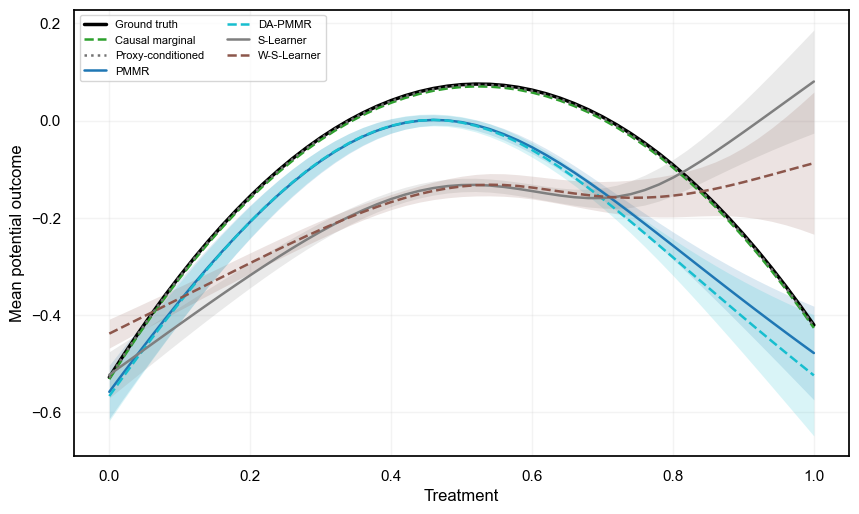

In [12]:
global_methods = ordered_existing_methods(
    global_curves_df.loc[global_curves_df["curve_type"] == "prediction", "method"].unique()
)

# None = usar todos
GLOBAL_METHODS = [
    "PMMR",
    "Weighted PMMR",
    "S-Learner",
    "Naive OOSR",
]

# Select predictor head used for global curves to avoid interleaving artifacts.
GLOBAL_CURVE_PREDICTOR_TYPES = ("mean_or_primary",)
GLOBAL_CURVE_SEPARATE_PREDICTOR_TYPES = False

fig = plot_global_curves(
    global_curves_df,
    methods=GLOBAL_METHODS,
    predictor_types=GLOBAL_CURVE_PREDICTOR_TYPES,
    separate_predictor_types=GLOBAL_CURVE_SEPARATE_PREDICTOR_TYPES,
    method_order=METHOD_ORDER,
    labels=METHOD_LABELS,
    colors=METHOD_COLORS,
    linestyles=METHOD_LINESTYLES,
    confidence=CONFIDENCE,
    show_ci=True,
    figsize=(10, 5.8),
)
save_figure(fig, ANALYSIS_DIR / "global_curves_ci.png")
save_figure(fig, ANALYSIS_DIR / "global_curves_ci.pdf")
plt.show()


## Patient-Specific Surfaces

These figures are reconstructed from the saved `patient_curves.csv` files. Change `SURFACE_SEED`, `PATIENT_RANK`, and `SURFACE_METHODS` without retraining any model.

Surface methods:
['PMMR', 'Weighted PMMR', 'S-Learner', 'Naive OOSR']


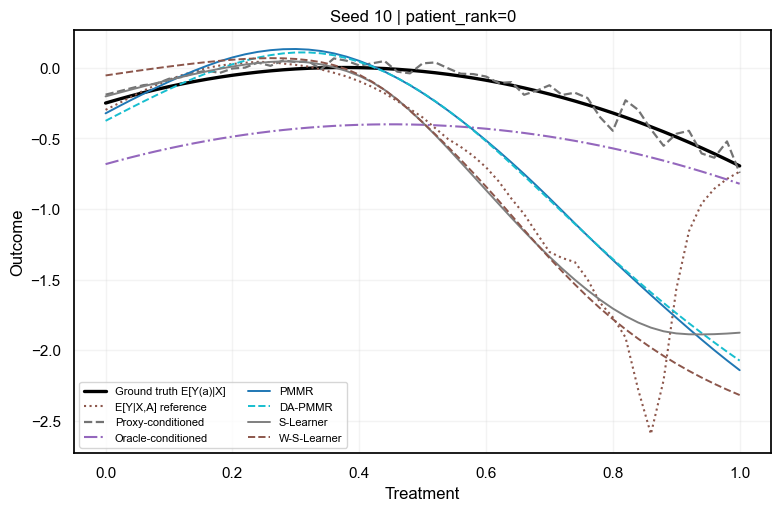

In [13]:
SURFACE_SEED = 10
PATIENT_RANK = 0

available_surface_methods = [
    method for method in patient_curves_df.loc[patient_curves_df["curve_type"] == "prediction", "method"].dropna().unique()
]

SURFACE_METHODS = [
    "PMMR",
    "Weighted PMMR",
    "S-Learner",
    "Naive OOSR",
]

print("Surface methods:")
print(SURFACE_METHODS)

fig = plot_patient_surface_from_table(
    patient_curves_df,
    seed=SURFACE_SEED,
    patient_rank=PATIENT_RANK,
    methods=SURFACE_METHODS,
    labels=METHOD_LABELS,
    colors=METHOD_COLORS,
    linestyles=METHOD_LINESTYLES,
    figsize=(9, 5.5),
)
save_figure(fig, ANALYSIS_DIR / f"patient_surface_seed_{SURFACE_SEED}_rank_{PATIENT_RANK}.png")
save_figure(fig, ANALYSIS_DIR / f"patient_surface_seed_{SURFACE_SEED}_rank_{PATIENT_RANK}.pdf")
plt.show()

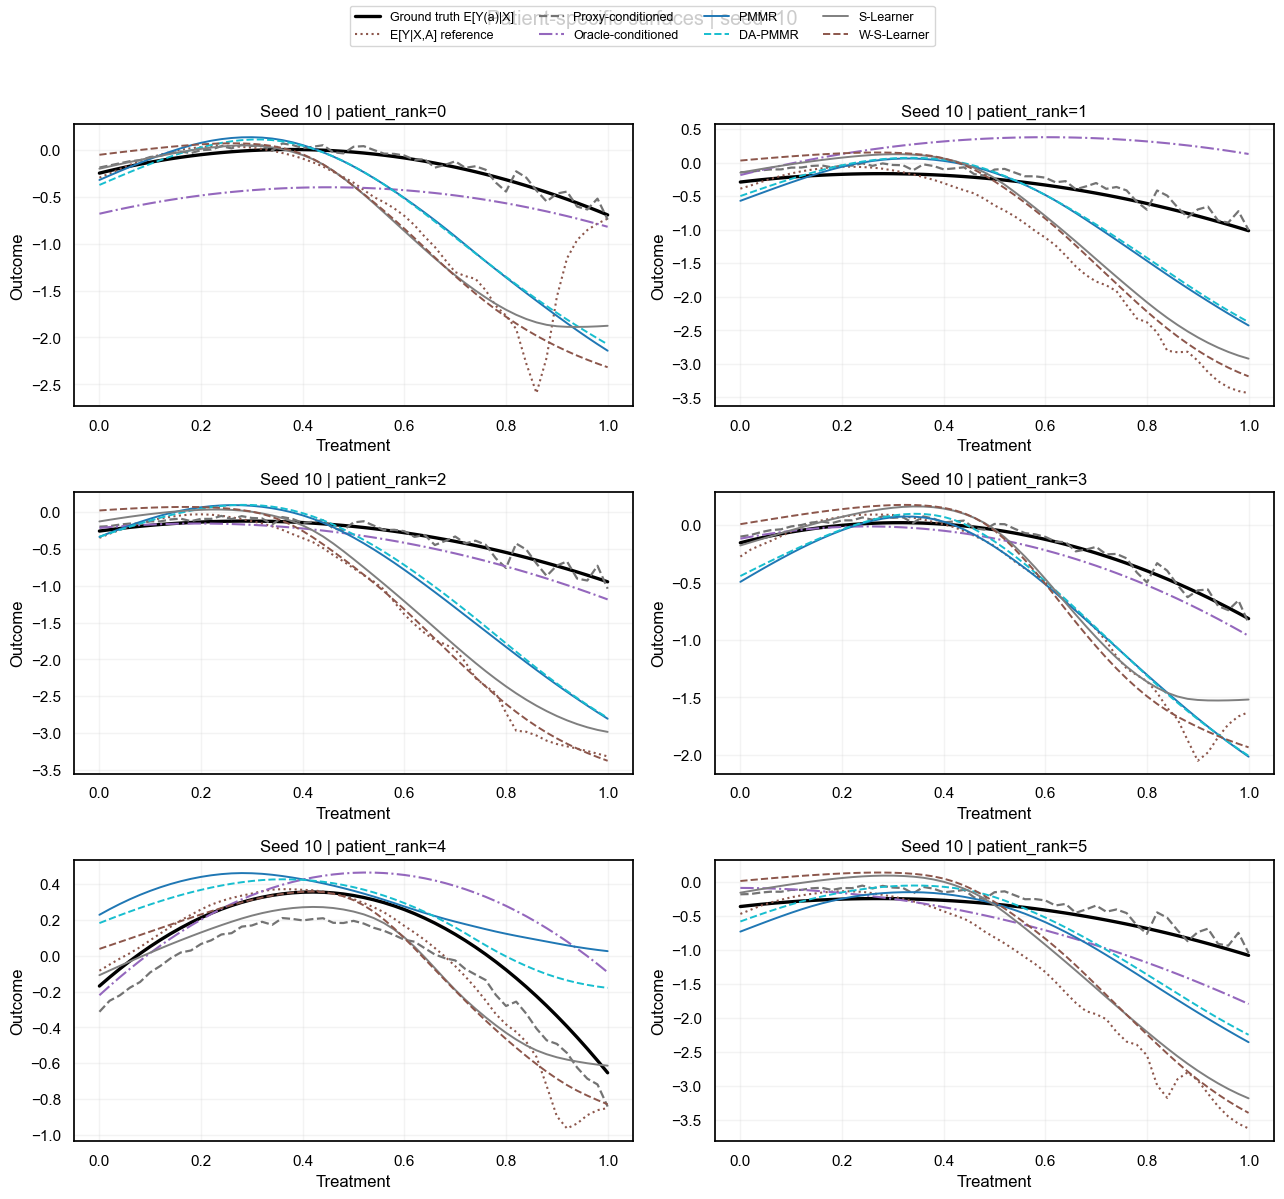

In [14]:
seed_metadata = patient_metadata_df[patient_metadata_df["seed"].astype(int) == SURFACE_SEED]
GALLERY_RANKS = list(range(min(6, int(seed_metadata["patient_rank"].nunique()))))

fig = plot_patient_surface_gallery_from_table(
    patient_curves_df,
    seed=SURFACE_SEED,
    patient_ranks=GALLERY_RANKS,
    methods=SURFACE_METHODS,
    labels=METHOD_LABELS,
    colors=METHOD_COLORS,
    linestyles=METHOD_LINESTYLES,
    ncols=2,
)
save_figure(fig, ANALYSIS_DIR / f"patient_surface_gallery_seed_{SURFACE_SEED}.png")
save_figure(fig, ANALYSIS_DIR / f"patient_surface_gallery_seed_{SURFACE_SEED}.pdf")
plt.show()

## Non-Parametric Statistical Tests

Oracle methods are excluded from the statistical comparison. For each metric, the paired block is `(dataset, seed)`. If a single dataset is loaded, this is equivalent to pairing by seed. The baseline is selected automatically as the best average non-oracle method for each metric.

In [15]:
candidate_test_methods = ordered_existing_methods(metrics_df["method"].unique())
TEST_METHODS = non_oracle_methods(candidate_test_methods)
TEST_METRICS = metrics_to_use

print("Methods included in statistical tests:")
print(TEST_METHODS)

tests = run_statistical_tests(
    metrics_df,
    TEST_METRICS,
    split=DEFAULT_SPLIT,
    methods=TEST_METHODS,
    metric_directions=METRIC_DIRECTIONS,
    alpha=ALPHA,
    block_cols=("dataset", "seed"),
)

print_statistical_tables(tests, alpha=ALPHA, tablefmt="grid", methods=TEST_METHODS)
written = export_analysis_tables(
    ANALYSIS_DIR,
    metric_summary=summary_df,
    publication_table=publication_table,
    tests=tests,
    test_methods=TEST_METHODS,
)
written

Methods included in statistical tests:
['PMMR', 'Weighted PMMR', 'NMMR-U', 'Weighted NMMR-U', 'NMMR-V', 'Weighted NMMR-V', 'KPV', 'Weighted KPV', 'DFPV', 'Weighted DFPV', 'S-Learner', 'Naive OOSR']

Friedman omnibus tests
+------------------------------+------------+-------------+---------------+--------------------+----------------------+--------------------+
| metric                       |   n_blocks |   n_methods | baseline      | higher_is_better   |   friedman_statistic |   friedman_p_value |
+==============================+============+=============+===============+====================+======================+====================+
| val_regret                   |         10 |          12 | Weighted DFPV | False              |              79.7077 |        1.6808e-12  |
+------------------------------+------------+-------------+---------------+--------------------+----------------------+--------------------+
| factual_mean_rmse            |         10 |          11 | S-Learner    

{'metric_summary_ci': WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/semisynthetic_article/analysis/seeds_1_10/metric_summary_ci.csv'),
 'publication_metric_table': WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/semisynthetic_article/analysis/seeds_1_10/publication_metric_table.csv'),
 'friedman_omnibus': WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/semisynthetic_article/analysis/seeds_1_10/friedman_omnibus.csv'),
 'friedman_posthoc': WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/semisynthetic_article/analysis/seeds_1_10/friedman_posthoc.csv'),
 'wilcoxon': WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/semisynthetic_article/analysis/seeds_1_10/wilcoxon.csv'),
 'friedman_posthoc_holm_table': WindowsPath('C:/Users/Alex/CODE

In [16]:
friedman_posthoc_table = statistical_test_table(tests["friedman_posthoc"], alpha=ALPHA, methods=TEST_METHODS)
wilcoxon_table = statistical_test_table(tests["wilcoxon"], alpha=ALPHA, methods=TEST_METHODS)

display(tests["friedman_omnibus"])
display(friedman_posthoc_table)
display(wilcoxon_table)

,metric,n_blocks,n_methods,baseline,higher_is_better,friedman_statistic,friedman_p_value
0,val_regret,10,12,Weighted DFPV,False,79.707692,1.680804e-12
1,factual_mean_rmse,10,11,S-Learner,False,78.145455,1.158216e-12
2,global_rmse,10,12,Weighted KPV,False,86.138462,9.480908e-14
3,local_rmse,10,12,PMMR,False,64.661538,1.247673e-09
4,mean_curve_rmse,10,12,PMMR,False,74.153846,1.969148e-11
5,mean_curve_argmax_abs_error,10,12,DFPV,False,82.152299,5.651542e-13
6,regret_causal_marginal,10,12,Weighted DFPV,False,79.123077,2.180031e-12
7,policy_mse_causal_marginal,10,12,Weighted DFPV,False,86.815385,6.994909e-14
8,policy_value_causal_marginal,10,12,Weighted DFPV,True,87.061538,6.262234e-14


method,PMMR,Weighted PMMR,NMMR-U,Weighted NMMR-U,NMMR-V,Weighted NMMR-V,KPV,Weighted KPV,DFPV,Weighted DFPV,S-Learner,Naive OOSR
metric,,,,,,,,,,,,
factual_mean_rmse,<1e-3,<1e-3,<1e-3,0.035,0.276*,0.624*,<1e-3,<1e-3,0.050*,<1e-3,1.000* (baseline),NaN
global_rmse,0.875*,0.376*,<1e-3,<1e-3,0.022,<1e-3,1.000*,1.000* (baseline),<1e-3,<1e-3,<1e-3,<1e-3
local_rmse,1.000* (baseline),0.645*,0.006,0.002,0.564*,0.605*,1.000*,0.605*,0.092*,<1e-3,<1e-3,<1e-3
mean_curve_argmax_abs_error,0.690*,0.529*,<1e-3,<1e-3,1.000*,1.000*,0.001,<1e-3,1.000* (baseline),0.529*,<1e-3,0.045
mean_curve_rmse,1.000* (baseline),1.000*,<1e-3,<1e-3,1.000*,0.427*,<1e-3,<1e-3,0.038,<1e-3,0.014,0.150*
policy_mse_causal_marginal,1.000*,1.000*,<1e-3,<1e-3,0.001,0.032,0.204*,0.007,0.771*,1.000* (baseline),<1e-3,0.002
policy_value_causal_marginal,1.000*,1.000*,<1e-3,<1e-3,<1e-3,0.009,0.547*,0.026,0.412*,1.000* (baseline),<1e-3,<1e-3
regret_causal_marginal,1.000*,1.000*,<1e-3,0.064*,<1e-3,0.005,0.470*,1.000*,0.327*,1.000* (baseline),<1e-3,<1e-3
val_regret,1.000*,1.000*,<1e-3,0.109*,<1e-3,0.003,0.314*,1.000*,0.283*,1.000* (baseline),<1e-3,<1e-3


method,PMMR,Weighted PMMR,NMMR-U,Weighted NMMR-U,NMMR-V,Weighted NMMR-V,KPV,Weighted KPV,DFPV,Weighted DFPV,S-Learner,Naive OOSR
metric,,,,,,,,,,,,
factual_mean_rmse,0.011,0.011,0.011,0.011,0.011,0.011,0.011,0.011,0.011,0.011,1.000* (baseline),NaN
global_rmse,0.012,0.012,0.012,0.012,0.012,0.012,0.012,1.000* (baseline),0.012,0.012,0.012,0.012
local_rmse,1.000* (baseline),0.160*,0.026,0.026,0.055*,0.029,0.055*,0.049,0.026,0.020,0.012,0.012
mean_curve_argmax_abs_error,0.023,0.023,0.012,0.012,0.078*,0.039,0.012,0.012,1.000* (baseline),0.021,0.012,0.039
mean_curve_rmse,1.000* (baseline),0.193*,0.012,0.012,0.097*,0.012,0.012,0.012,0.020,0.012,0.012,0.012
policy_mse_causal_marginal,0.647*,0.647*,0.012,0.012,0.012,0.012,0.012,0.012,0.211*,1.000* (baseline),0.012,0.012
policy_value_causal_marginal,0.168*,0.168*,0.012,0.012,0.012,0.012,0.012,0.012,0.168*,1.000* (baseline),0.012,0.012
regret_causal_marginal,0.211*,0.211*,0.012,0.041,0.012,0.012,0.016,0.275*,0.210*,1.000* (baseline),0.012,0.016
val_regret,0.387*,0.387*,0.012,0.041,0.012,0.012,0.021,0.387*,0.210*,1.000* (baseline),0.012,0.012


## Optional LaTeX Export

In [17]:
(ANALYSIS_DIR / "publication_metric_table.tex").write_text(publication_table.to_latex(escape=False), encoding="utf-8")
friedman_posthoc_table.to_latex(ANALYSIS_DIR / "friedman_posthoc_holm_table.tex", escape=False)
wilcoxon_table.to_latex(ANALYSIS_DIR / "wilcoxon_holm_table.tex", escape=False)
print(f"LaTeX tables written to {ANALYSIS_DIR}")








LaTeX tables written to C:\Users\Alex\CODE\optimal_treatment_proximal_inference\weighted_proximal_oosr\results\semisynthetic_article\analysis\seeds_1_10
